# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

## Chuẩn bị chung

 

In [1]:
import json
import os
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch  :", torch.__version__)
print("device :", device)


# Hai hàm tiện ích của Lab 2 (A.1)
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

torch  : 2.11.0+cu128
device : cuda


In [2]:
# Cấu hình chung cho cả bốn bài (Lab 2, A.2 Bước 2)
DATA_ROOT = Path("VinaFood21")   # sửa đường dẫn cho đúng máy
GDRIVE_URL = "https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view"

BATCH = 32
NUM_WORKERS = 0 if os.name == "nt" else 2
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # mean/std của ImageNet

IMG_SIZE = 64      # Bài 1, 2
R18_SIZE = 96      # Bài 3 (không dùng 64: layer4 chỉ còn 2x2, xem B.5 Bước 4)
R50_SIZE = 224     # Bài 4
EPOCHS = 20        # Bài 1 - 3
EPOCHS_R50 = 5     # Bài 4: nặng, giảm xuống nếu chạy trên CPU


def find_data_root(search_dir):
    # Tìm thư mục cha của train/ trong cây thư mục vừa giải nén
    for p in sorted(Path(search_dir).rglob("train")):
        if p.is_dir() and any(c.is_dir() for c in p.iterdir()):
            return p.parent
    return None


if not (DATA_ROOT / "train").is_dir():
    # Chưa có dữ liệu: thử tải tự động (Colab). Nếu lỗi thì tải tay theo link ở đầu notebook
    try:
        import shutil
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(GDRIVE_URL, "vinafood21.zip", quiet=False, fuzzy=True)
        shutil.unpack_archive("vinafood21.zip", "vinafood21_raw")
        DATA_ROOT = find_data_root("vinafood21_raw") or DATA_ROOT
    except Exception as e:
        print("Không tải được tự động:", type(e).__name__, "-", e)

HAS_DATA = (DATA_ROOT / "train").is_dir()
READY = HAS_DATA
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

CLASSES = [f"lop_{i}" for i in range(21)]
if READY:
    CLASSES = sorted(d.name for d in (DATA_ROOT / "train").iterdir() if d.is_dir())
NUM_CLASSES = len(CLASSES)

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=ec479e56-c7f3-4678-9489-46669adac8c2
To: /kaggle/working/vinafood21.zip
100%|██████████| 2.71G/2.71G [00:38<00:00, 70.6MB/s]


Tìm thấy dữ liệu: True - /kaggle/working/vinafood21_raw/VinaFood21


In [3]:
# Transform và DataLoader (Lab 2, A.2 Bước 3 - 4)
def build_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if not augment:
        return eval_tf, eval_tf
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


def split_indices(n, has_val, has_test):
    # Cùng một phép chia cho mọi bài: random_split + generator seed 42.
    # Chỉ tách val (và test) từ train khi bản tải về không có sẵn thư mục val/ (test/).
    n_val = 0 if has_val else int(0.1 * n)
    n_test = 0 if has_test else int(0.1 * n)
    lengths = [n - n_val - n_test, n_val, n_test]
    parts = random_split(range(n), lengths, generator=torch.Generator().manual_seed(SEED))
    return [p.indices for p in parts]


_LOADER_CACHE = {}


def get_loaders(img_size, augment=True):
    key = (img_size, augment)
    if key in _LOADER_CACHE:
        return _LOADER_CACHE[key]

    train_tf, eval_tf = build_transforms(img_size, augment)
    full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    full_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    assert full_train.classes == CLASSES

    val_dir, test_dir = DATA_ROOT / "val", DATA_ROOT / "test"
    has_val = val_dir.is_dir()
    has_test = test_dir.is_dir() and any(p.is_dir() for p in test_dir.iterdir())
    train_idx, val_idx, test_idx = split_indices(len(full_train), has_val, has_test)

    train_ds = Subset(full_train, train_idx)
    val_ds = datasets.ImageFolder(val_dir, eval_tf) if has_val else Subset(full_eval, val_idx)
    test_ds = datasets.ImageFolder(test_dir, eval_tf) if has_test else Subset(full_eval, test_idx)
    if not has_test:
        print("Không có test/ có nhãn: tách 10% từ train làm test (seed 42).")

    kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
    loaders = (
        DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **kw),
        DataLoader(val_ds, shuffle=False, **kw),
        DataLoader(test_ds, shuffle=False, **kw),
    )
    _LOADER_CACHE[key] = loaders
    return loaders

số lớp         : 21
train/val/test : 9040 / 1004 / 6682
thứ tự lớp     : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)

ảnh/lớp (train gốc): min 215, max 910, tỉ lệ max/min 4.23


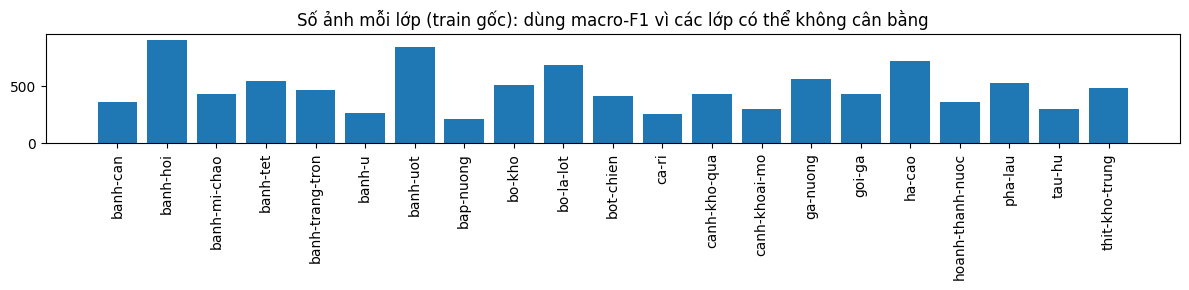

In [4]:
# Kiểm tra dữ liệu: shape một ảnh / một batch và phân phối lớp (Lab 2, A.2 Bước 5)
if READY:
    train_dl, val_dl, test_dl = get_loaders(IMG_SIZE, augment=True)
    print("số lớp         :", NUM_CLASSES)
    print("train/val/test :", len(train_dl.dataset), "/", len(val_dl.dataset), "/", len(test_dl.dataset))
    print("thứ tự lớp     :", CLASSES[:5], "...")

    anh, nhan = train_dl.dataset[0]
    xb, yb = next(iter(train_dl))
    show("một ảnh sau transform", anh)
    show("một batch vào model", xb)
    show("nhãn", yb)

    counts = np.bincount(datasets.ImageFolder(DATA_ROOT / "train").targets, minlength=NUM_CLASSES)
    print(f"\nảnh/lớp (train gốc): min {counts.min()}, max {counts.max()}, tỉ lệ max/min {counts.max() / counts.min():.2f}")
    plt.figure(figsize=(12, 3))
    plt.bar(range(NUM_CLASSES), counts)
    plt.xticks(range(NUM_CLASSES), CLASSES, rotation=90)
    plt.title("Số ảnh mỗi lớp (train gốc): dùng macro-F1 vì các lớp có thể không cân bằng")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu: các ô huấn luyện sẽ tự bỏ qua, phần kiểm tra kiến trúc vẫn chạy.")

In [5]:
# Khung huấn luyện và đánh giá (Lab 2, B.7)
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred


def fit(model, train_dl, val_dl, criterion, optimizer, epochs):
    # Huấn luyện, ghi lịch sử; cuối cùng nạp lại trọng số của epoch có val loss thấp nhất
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "sec": []}
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        hist["sec"].append(time.perf_counter() - t0)
        for k, v in zip(("train_loss", "train_acc", "val_loss", "val_acc"), (tr_loss, tr_acc, va_loss, va_acc)):
            hist[k].append(v)
        if va_loss < best_loss:
            best_loss, hist["best_epoch"] = va_loss, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}   val {va_loss:.4f}/{va_acc:.4f}   {hist['sec'][-1]:.1f}s")
    model.load_state_dict(best_state)
    return hist


def split_epoch(hist, thr=0.1):
    # Epoch đầu tiên val loss vượt train loss quá thr (tương đối): hai đường bắt đầu tách nhau
    for ep, (t, v) in enumerate(zip(hist["train_loss"], hist["val_loss"]), 1):
        if v > (1 + thr) * t:
            return ep
    return None


def plot_curves(hist, title, mark_split=False):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(ep, hist["train_loss"], label="train loss")
    ax[0].plot(ep, hist["val_loss"], label="val loss")
    ax[0].axvline(hist["best_epoch"], color="gray", ls=":", label=f"val loss thấp nhất (epoch {hist['best_epoch']})")
    se = split_epoch(hist)
    if mark_split and se:
        ax[0].axvline(se, color="red", ls="--", label=f"hai đường tách nhau (epoch {se})")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("loss")
    ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train acc")
    ax[1].plot(ep, hist["val_acc"], label="val acc")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("accuracy")
    ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


RESULTS = {}   # tag -> dict kết quả, dùng cho bảng tổng hợp
RESULTS_DIR = Path("results")   # mỗi lần chạy lưu 1 file json để các notebook/bài khác đọc lại khi so sánh
RESULTS_DIR.mkdir(exist_ok=True)


def save_result(tag):
    slug = "".join(ch if ch.isalnum() else "_" for ch in tag.lower())
    light = {k: v for k, v in RESULTS[tag].items() if k not in ("y_true", "y_pred")}
    with open(RESULTS_DIR / f"{slug}.json", "w", encoding="utf-8") as f:
        json.dump({"tag": tag, **light}, f, ensure_ascii=False, default=float)


def load_results():
    for p in sorted(RESULTS_DIR.glob("*.json")):
        with open(p, encoding="utf-8") as f:
            r = json.load(f)
        RESULTS.setdefault(r.pop("tag"), r)


def show_report(tag, res, mark_split=False):
    hist, y_true, y_pred = res["hist"], res["y_true"], res["y_pred"]
    print(f"\n--- {tag}: kết quả trên tập test (nạp lại epoch {hist['best_epoch']}) ---")
    print(f"tham số: {res['params']:,} (được học: {res['trainable']:,}) | {res['sec_epoch']:.1f} giây/epoch")
    display(pd.DataFrame({
        "accuracy": [res["accuracy"]], "precision (macro)": [res["precision"]],
        "recall (macro)": [res["recall"]], "F1 (macro)": [res["macro_f1"]],
    }, index=[tag]).round(4))

    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    display(pd.DataFrame({"lớp": CLASSES, "precision": p, "recall": r, "F1": f, "số ảnh test": s}).round(4))

    plot_curves(hist, tag, mark_split)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(13, 11))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                annot_kws={"size": 6}, cbar=False)
    plt.xlabel("dự đoán")
    plt.ylabel("thực tế")
    plt.title(f"Confusion matrix {NUM_CLASSES}x{NUM_CLASSES}: {tag}")
    plt.tight_layout()
    plt.show()

    off = cm.copy()
    np.fill_diagonal(off, 0)
    print("Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):")
    for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:5], off.shape)):
        if off[i, j] > 0:
            print(f"  {CLASSES[i]} -> {CLASSES[j]}: {off[i, j]} ảnh")


def train_and_report(tag, make_model, img_size, lr, epochs, augment=True, mark_split=False):
    # Một lần chạy hoàn chỉnh: tạo model -> Adam -> huấn luyện -> đánh giá test -> báo cáo
    if not READY:
        print(f"[{tag}] chưa có dữ liệu VinaFood21 -> bỏ qua huấn luyện.")
        return None
    train_dl, val_dl, test_dl = get_loaders(img_size, augment)
    seed_everything()
    model = make_model().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)   # chỉ tham số cần học
    print(f"== {tag} | resize {img_size} | augment={augment} | Adam lr={lr} | "
          f"tham số {n_params(model):,} (được học {n_params(model, True):,})")

    hist = fit(model, train_dl, val_dl, criterion, optimizer, epochs)
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    RESULTS[tag] = dict(
        resize=f"{img_size}x{img_size}", params=n_params(model), trainable=n_params(model, True),
        sec_epoch=float(np.mean(hist["sec"])), accuracy=accuracy_score(y_true, y_pred),
        precision=p, recall=r, macro_f1=f1, hist=hist, y_true=y_true, y_pred=y_pred)
    save_result(tag)
    show_report(tag, RESULTS[tag], mark_split)
    return model


def compare_models(names):
    names = [n for n in names if n in RESULTS]
    return pd.DataFrame({
        n: {"tham số": RESULTS[n]["params"], "giây/epoch": RESULTS[n]["sec_epoch"],
            "accuracy": RESULTS[n]["accuracy"], "macro-F1": RESULTS[n]["macro_f1"]}
        for n in names}).T.round(4)


load_results()   # nạp kết quả các bài đã chạy trước đó (nếu có)

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

In [6]:
# Tải thử model pretrained (Lab 2, B.6 Bước 1)
HAS_HF = False
try:
    from transformers import ResNetForImageClassification
    ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
    HAS_HF = True
except Exception as e:
    print("Không tải được pretrained model:", type(e).__name__)
    print("Bỏ qua Bài 4; phần còn lại của notebook vẫn chạy.")


# Backbone pretrained + classifier mới (Lab 2, B.6 Bước 2)
class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)
        self.freeze_backbone = freeze_backbone

        if freeze_backbone:                   # feature extraction
            for p in self.resnet.parameters():
                p.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:              # backbone đóng băng thì BN cũng không được cập nhật thống kê
            self.resnet.eval()
        return self

    def forward(self, images):
        features = self.resnet(images).pooler_output    # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)     # [B, 2048]
        return self.classifier(features)                # [B, 21]


if HAS_HF:
    fe = PretrainedResnet(21, freeze_backbone=True)
    ft = PretrainedResnet(21, freeze_backbone=False)
    x = torch.rand(2, 3, R50_SIZE, R50_SIZE)
    with torch.no_grad():
        show("ảnh vào", x)
        show("pooler_output", fe.resnet(x).pooler_output)
        show("logits", fe.eval()(x))

    print(f"\n{'chế độ':<22}{'tổng':>14}{'được cập nhật':>16}{'lr':>8}")
    print(f"{'feature extraction':<22}{n_params(fe):>14,}{n_params(fe, True):>16,}{'1e-3':>8}")
    print(f"{'fine-tuning':<22}{n_params(ft):>14,}{n_params(ft, True):>16,}{'1e-4':>8}")
    assert n_params(fe) == 23_551_061 and n_params(fe, True) == 43_029 and n_params(ft, True) == 23_551_061

    # mean/std đi kèm model phải trùng với MEAN, STD đang dùng ở transform
    try:
        from transformers import AutoImageProcessor
        proc = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
        assert tuple(proc.image_mean) == MEAN and tuple(proc.image_std) == STD
        print("\nmean/std của AutoImageProcessor trùng với MEAN, STD đang dùng:", MEAN, STD)
    except Exception as e:
        print("\nKhông kiểm được processor:", type(e).__name__, "- dùng mean/std ImageNet:", MEAN, STD)
    del fe, ft

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ảnh vào                      (2, 3, 224, 224)
pooler_output                (2, 2048, 1, 1)
logits                       (2, 21)

chế độ                          tổng   được cập nhật      lr
feature extraction        23,551,061          43,029    1e-3
fine-tuning               23,551,061      23,551,061    1e-4


preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]


mean/std của AutoImageProcessor trùng với MEAN, STD đang dùng: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

== ResNet-50 feature extraction | resize 224 | augment=True | Adam lr=0.001 | tham số 23,551,061 (được học 43,029)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.1150/0.4619   val 1.5857/0.6175   89.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch  4  train 1.0029/0.7305   val 0.9733/0.7151   89.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  5  train 0.9132/0.7509   val 0.9096/0.7301   87.9s

--- ResNet-50 feature extraction: kết quả trên tập test (nạp lại epoch 5) ---
tham số: 23,551,061 (được học: 43,029) | 89.2 giây/epoch


,accuracy,precision (macro),recall (macro),F1 (macro)
ResNet-50 feature extraction,0.6966,0.7223,0.7023,0.6991


,lớp,precision,recall,F1,số ảnh test
0,banh-can,0.6715,0.7635,0.7146,241
1,banh-hoi,0.6718,0.6474,0.6594,607
2,banh-mi-chao,0.7246,0.8374,0.7769,289
3,banh-tet,0.9234,0.6621,0.7712,364
4,banh-trang-tron,0.7652,0.6537,0.7051,309
5,banh-u,0.7538,0.8352,0.7925,176
6,banh-uot,0.5844,0.5500,0.5667,560
7,bap-nuong,0.9627,0.9021,0.9314,143
8,bo-kho,0.5583,0.6657,0.6073,338
9,bo-la-lot,0.6731,0.8406,0.7476,458


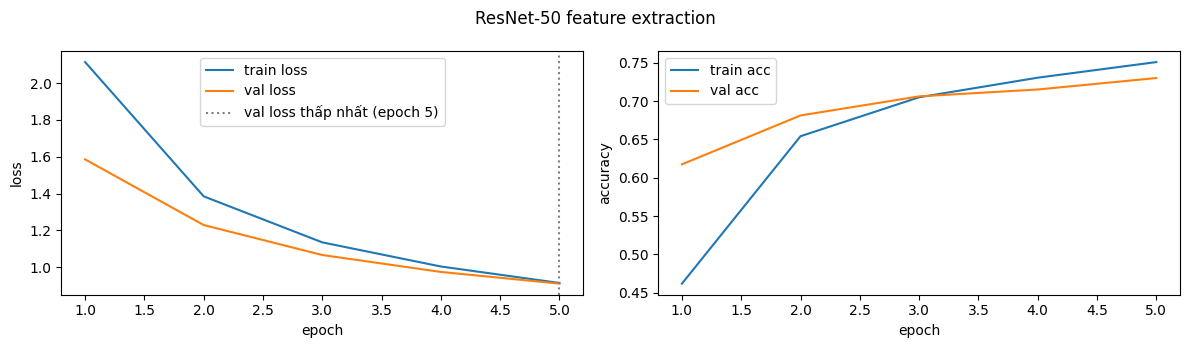

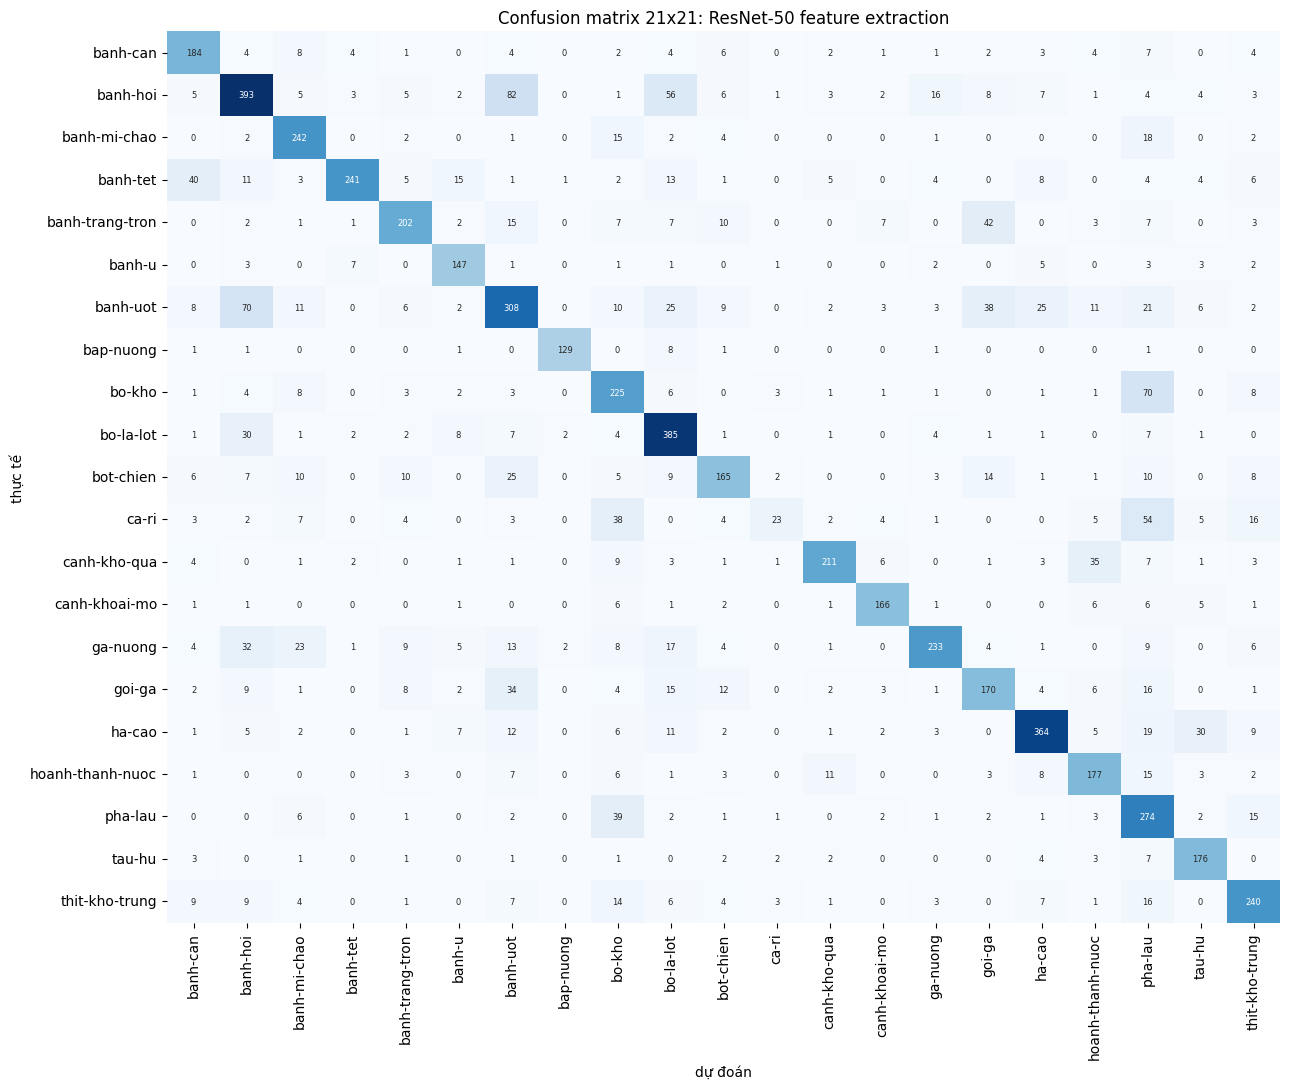

Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):
  banh-hoi -> banh-uot: 82 ảnh
  bo-kho -> pha-lau: 70 ảnh
  banh-uot -> banh-hoi: 70 ảnh
  banh-hoi -> bo-la-lot: 56 ảnh
  ca-ri -> pha-lau: 54 ảnh


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

== ResNet-50 fine-tuning | resize 224 | augment=True | Adam lr=0.0001 | tham số 23,551,061 (được học 23,551,061)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7201/0.2029   val 2.2163/0.4432   102.7s


...

epoch  4  train 0.6619/0.7975   val 0.5565/0.8197   103.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  5  train 0.5314/0.8342   val 0.4837/0.8466   103.5s

--- ResNet-50 fine-tuning: kết quả trên tập test (nạp lại epoch 5) ---
tham số: 23,551,061 (được học: 23,551,061) | 103.0 giây/epoch


,accuracy,precision (macro),recall (macro),F1 (macro)
ResNet-50 fine-tuning,0.8123,0.818,0.8102,0.8098


,lớp,precision,recall,F1,số ảnh test
0,banh-can,0.7580,0.8838,0.8161,241
1,banh-hoi,0.7982,0.8731,0.8340,607
2,banh-mi-chao,0.9387,0.8478,0.8909,289
3,banh-tet,0.9783,0.7445,0.8456,364
4,banh-trang-tron,0.8885,0.7735,0.8270,309
5,banh-u,0.7430,0.9034,0.8154,176
6,banh-uot,0.7719,0.7250,0.7477,560
7,bap-nuong,0.9324,0.9650,0.9485,143
8,bo-kho,0.6722,0.7219,0.6961,338
9,bo-la-lot,0.8520,0.9301,0.8894,458


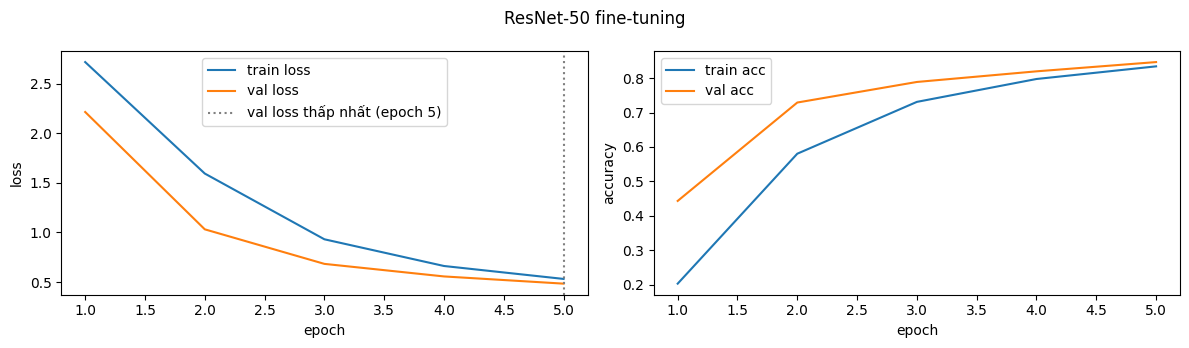

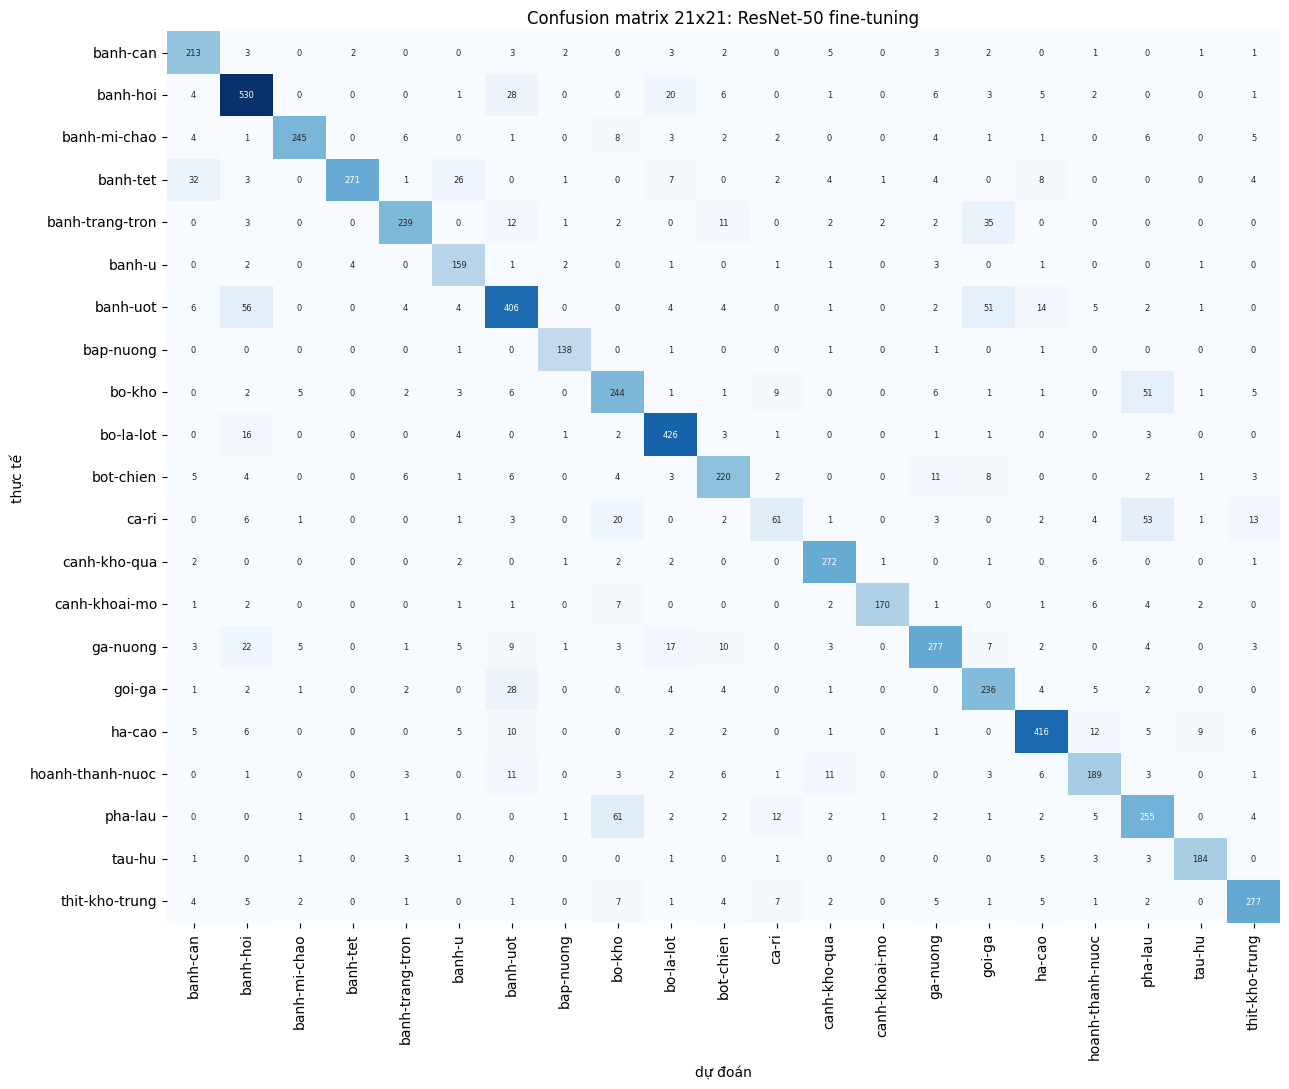

Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):
  pha-lau -> bo-kho: 61 ảnh
  banh-uot -> banh-hoi: 56 ảnh
  ca-ri -> pha-lau: 53 ảnh
  banh-uot -> goi-ga: 51 ảnh
  bo-kho -> pha-lau: 51 ảnh


In [7]:
# Hai chế độ (optimizer chỉ nhận tham số requires_grad: xem train_and_report)
if HAS_HF:
    _ = train_and_report("ResNet-50 feature extraction", lambda: PretrainedResnet(NUM_CLASSES, freeze_backbone=True),
                         R50_SIZE, lr=1e-3, epochs=EPOCHS_R50)
    _ = train_and_report("ResNet-50 fine-tuning", lambda: PretrainedResnet(NUM_CLASSES, freeze_backbone=False),
                         R50_SIZE, lr=1e-4, epochs=EPOCHS_R50)

In [8]:
# So sánh bốn mô hình và chênh lệch giữa transfer learning với huấn luyện từ đầu (Bài 3)
four = ["LeNet-5 (AvgPool)", "GoogLeNet rút gọn", "ResNet-18 từ đầu (có augment)",
        "ResNet-50 feature extraction", "ResNet-50 fine-tuning"]
display(compare_models(four))
scratch = RESULTS.get("ResNet-18 từ đầu (có augment)")
for tag in ("ResNet-50 feature extraction", "ResNet-50 fine-tuning"):
    if scratch and tag in RESULTS:
        d = RESULTS[tag]["macro_f1"] - scratch["macro_f1"]
        print(f"{tag} so với ResNet-18 từ đầu: macro-F1 {RESULTS[tag]['macro_f1']:.4f} vs {scratch['macro_f1']:.4f} ({d:+.4f})")

,tham số,giây/epoch,accuracy,macro-F1
ResNet-50 feature extraction,23551061.0,89.1986,0.6966,0.6991
ResNet-50 fine-tuning,23551061.0,103.0025,0.8123,0.8098


---
## Bảng tổng hợp kết quả

In [9]:
# Bảng tổng hợp lấy từ các lần chạy ở trên (Lab 2, C.2)
ORDER = ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn", "ResNet-18 từ đầu (có augment)",
         "ResNet-18 từ đầu (không augment)", "ResNet-50 feature extraction", "ResNet-50 fine-tuning"]
rows = [{
    "Mô hình": tag, "Resize": r["resize"], "Tham số": f"{r['params']:,}",
    "Tham số được học": f"{r['trainable']:,}", "Giây/epoch": round(r["sec_epoch"], 1),
    "Accuracy": round(r["accuracy"], 4), "macro-F1": round(r["macro_f1"], 4),
} for tag, r in sorted(RESULTS.items(), key=lambda kv: ORDER.index(kv[0]) if kv[0] in ORDER else 99)]

if rows:
    summary = pd.DataFrame(rows)
    display(summary)
    summary.to_csv("ket_qua_tong_hop.csv", index=False)
else:
    print("Chưa có kết quả huấn luyện (thiếu dữ liệu).")

,Mô hình,Resize,Tham số,Tham số được học,Giây/epoch,Accuracy,macro-F1
0,ResNet-50 feature extraction,224x224,"23,551,061","43,029",89.2,0.6966,0.6991
1,ResNet-50 fine-tuning,224x224,"23,551,061","23,551,061",103.0,0.8123,0.8098
